# Đánh giá dự báo PM2.5 từ t+1 đến t+4

So sánh checkpoint được chọn trong ô nạp model với hai baseline trên cùng toàn bộ tập test. Mỗi cửa sổ đóng góp một cặp dự báo–quan sát cho mỗi mốc từ **t+1** đến **t+4**.

- **Persistence:** dùng PM2.5 của giờ gần nhất cho cả bốn mốc.
- **Seasonal naive:** dùng PM2.5 của giờ tương ứng ngày hôm trước cho từng mốc.

Chọn kernel của môi trường `aqi_forecast` rồi bấm **Run All** để cập nhật bảng và hình.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

cwd = Path.cwd()
candidates = (cwd, cwd / "HN_PM25_forecasting", *cwd.parents)
root = next((path for path in candidates if (path / "configs/common.yaml").is_file()), None)
if root is None:
    raise FileNotFoundError("Mở notebook từ thư mục HN_PM25_forecasting hoặc workspace của dự án.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.baselines import persistence_forecast, seasonal_naive_forecast
from src.data_pipeline import load_prepared_split
from src.metrics import compute_forecast_metrics
from src.preprocessing import inverse_targets, load_scalers
from src.utils import load_config

config = load_config(root / "configs/common.yaml")
X, y = load_prepared_split(config.processed, "test")
scalers = load_scalers(config.processed / "scalers.json")
X_raw = scalers.x.inverse_transform(X.reshape(-1, X.shape[-1])).reshape(X.shape)
y_raw = inverse_targets(y, scalers)

print(f"Dữ liệu: {config.processed.name}")
print(f"Tập test: {len(y_raw):,} cửa sổ, {y_raw.shape[1]} mốc dự báo mỗi cửa sổ.")

Dữ liệu: pm25_24x4_complete_v1
Tập test: 983 cửa sổ, 4 mốc dự báo mỗi cửa sổ.


In [2]:
import tensorflow as tf

from scripts.evaluate import predict_batches
from src.utils import dataset_fingerprint, read_json, sha256

checkpoint = root / "runs/cnn_lstm/cnn_lstm-test/seed_42/best.keras"
metadata = read_json(checkpoint.parent / "run_metadata.json")
if sha256(checkpoint) != metadata["checkpoint_sha256"]:
    raise ValueError("Checkpoint đã thay đổi so với metadata của lần train.")
if dataset_fingerprint(config.processed) != metadata["dataset_fingerprint"]:
    raise ValueError("Dữ liệu hiện tại khác dữ liệu được ghi trong metadata của model.")

with tf.device("/CPU:0"):
    model = tf.keras.models.load_model(checkpoint, compile=False)
    model_forecasts = inverse_targets(predict_batches(model, X), scalers)

model_name = metadata["model_name"].replace("_", "-").upper()
model_label = f"{model_name} (seed {metadata['seed']})"
print(f"{model_label}: {len(model_forecasts):,} cửa sổ test.")

CNN-LSTM (seed 42): 983 cửa sổ test.


## Kết quả theo mốc dự báo

Mỗi dòng tổng hợp sai số trên toàn bộ cửa sổ test tại một mốc. MAE và RMSE có đơn vị µg/m³.

In [3]:
predictions = {
    model_label: model_forecasts,
    "Persistence": persistence_forecast(X_raw),
    "Seasonal naive": seasonal_naive_forecast(X_raw),
}
scores = {
    name: compute_forecast_metrics(y_raw, prediction)["per_horizon"]
    for name, prediction in predictions.items()
}
horizon_hours = range(1, y_raw.shape[1] + 1)
metric_labels = {
    "mae": "MAE (µg/m³)",
    "rmse": "RMSE (µg/m³)",
    "smape_pct": "sMAPE (%)",
    "r2": "R²",
    "n_pairs": "Số cặp",
}
table = pd.DataFrame([
    {"Mốc": f"t+{hour}", "Mô hình": name, **metrics[hour - 1]}
    for hour in horizon_hours
    for name, metrics in scores.items()
])
display(
    table.set_index(["Mốc", "Mô hình"])[list(metric_labels)]
    .rename(columns=metric_labels)
    .round(3)
)

MAE (µg/m³)  RMSE (µg/m³)  sMAPE (%)     R²  Số cặp
Mốc Mô hình                                                                
t+1 CNN-LSTM (seed 42)        5.637         7.163     26.539  0.735     983
    Persistence               4.188         5.440     18.992  0.847     983
    Seasonal naive           10.442        13.820     45.626  0.012     983
t+2 CNN-LSTM (seed 42)        6.732         8.699     30.115  0.609     983
    Persistence               5.429         7.001     25.183  0.747     983
    Seasonal naive           10.442        13.820     45.651  0.013     983
t+3 CNN-LSTM (seed 42)        7.770         9.989     33.768  0.485     983
    Persistence               6.461         8.505     29.385  0.626     983
    Seasonal naive           10.441        13.820     45.649  0.013     983
t+4 CNN-LSTM (seed 42)        8.484        10.859     36.348  0.390     983
    Persistence               7.170         9.462     32.239  0.537     983
    Seasonal naive           10.441        13.820     45.654  0.012     983

## Dự báo và quan sát trên toàn bộ tập test

Mỗi hình dùng cùng thang đo PM2.5 cho model đã chọn và hai baseline. Trục ngang là thứ tự các cửa sổ test hợp lệ theo thời gian. Notebook xuất ba file PNG cho t+2, t+3 và t+4.

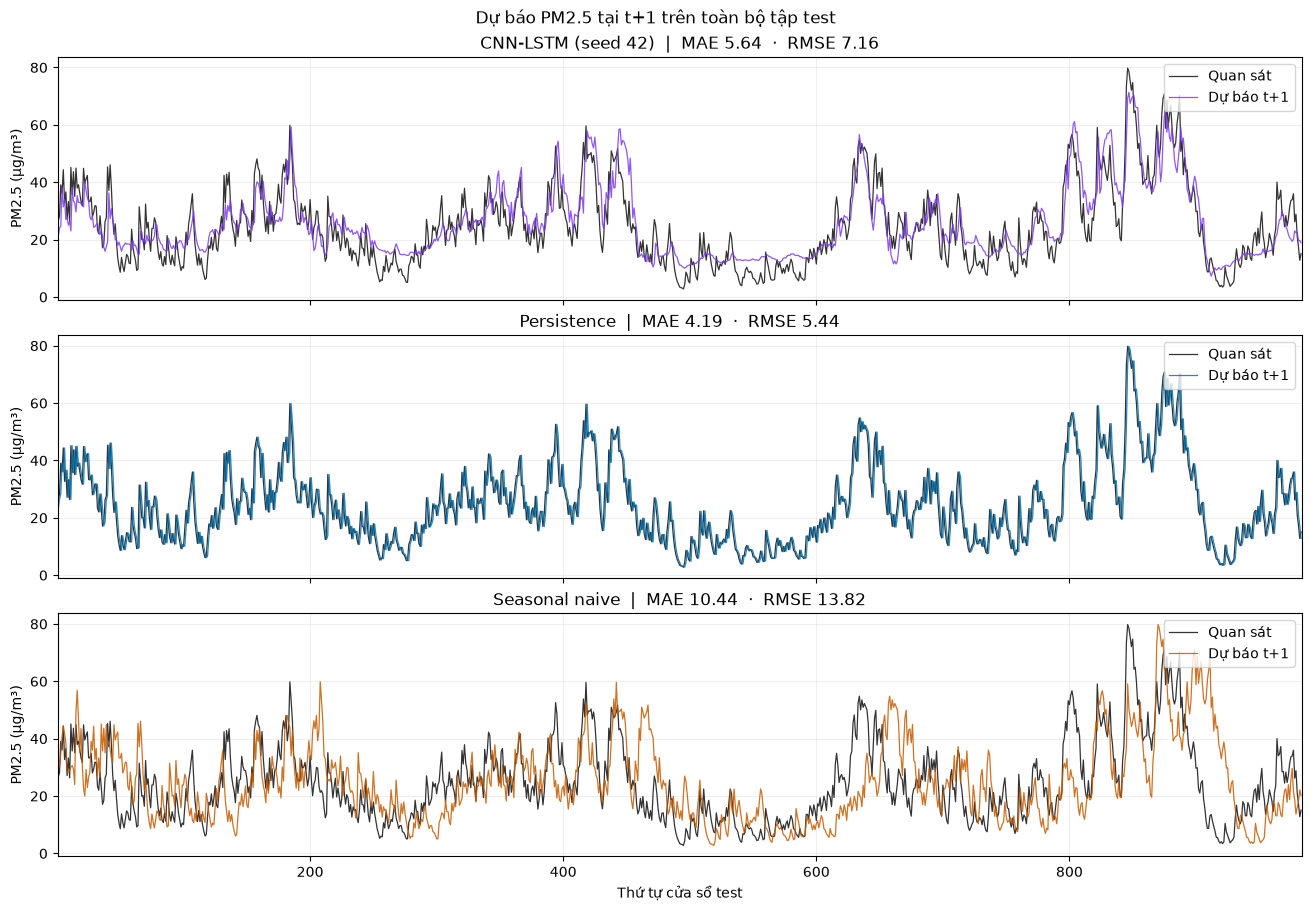

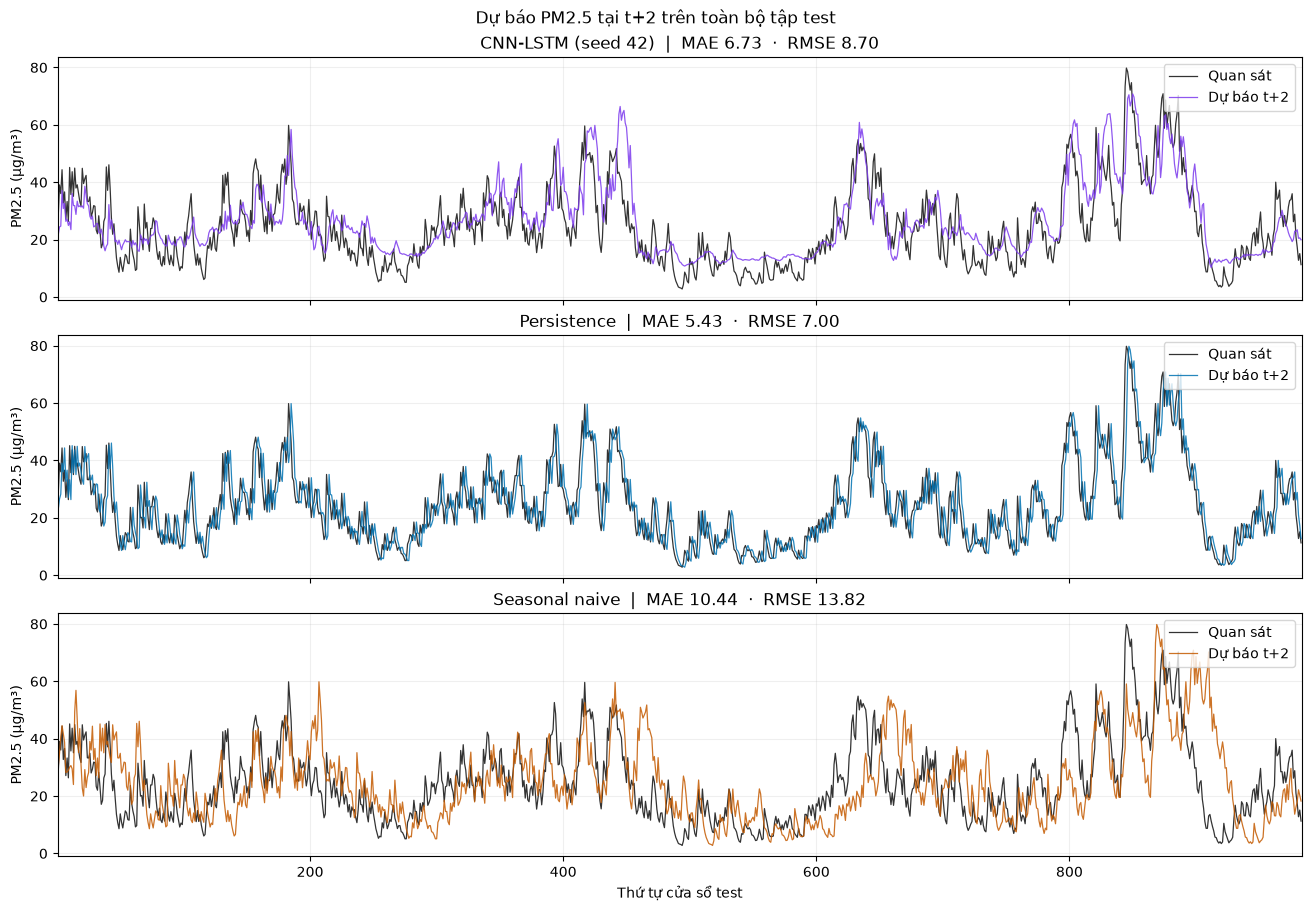

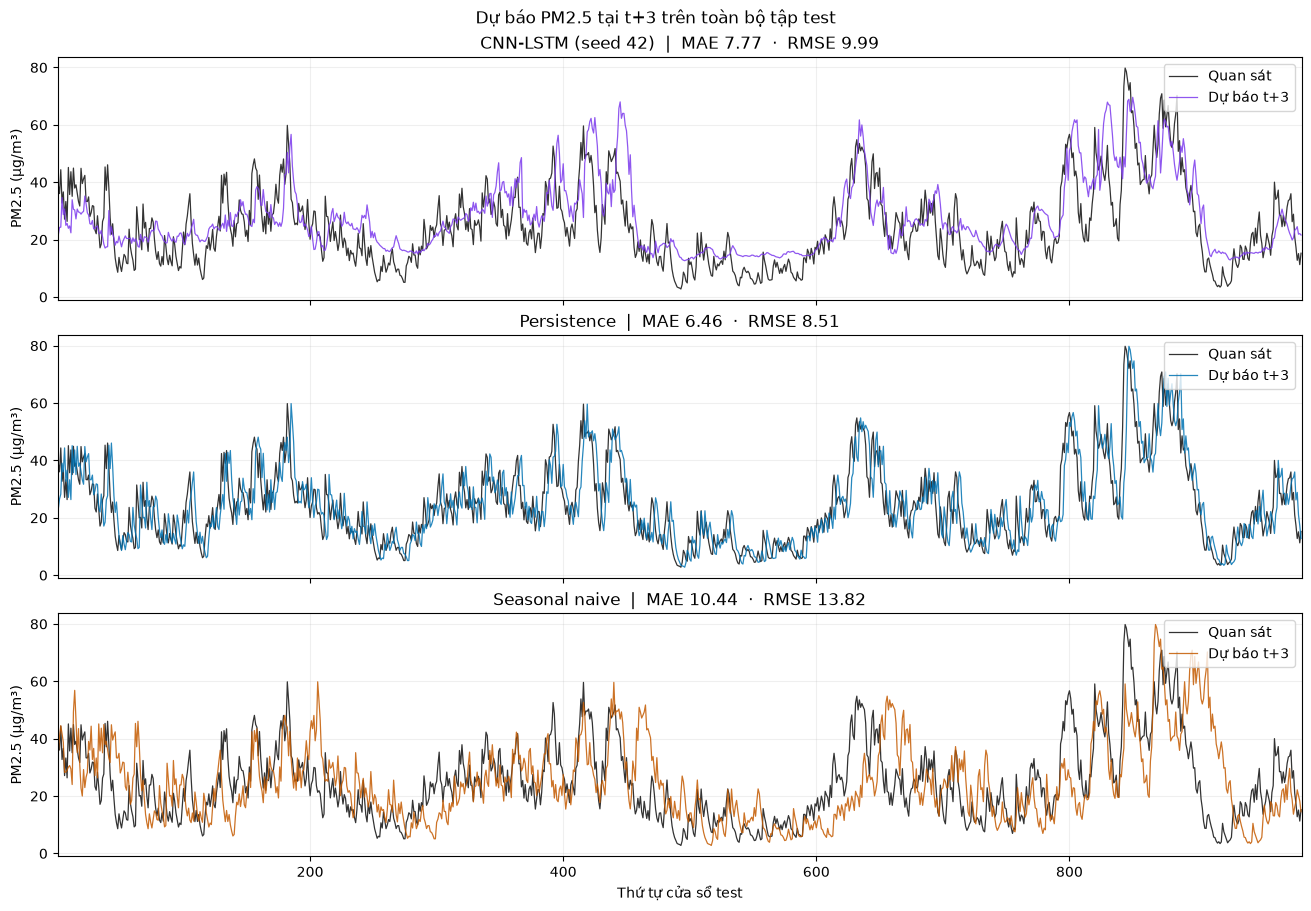

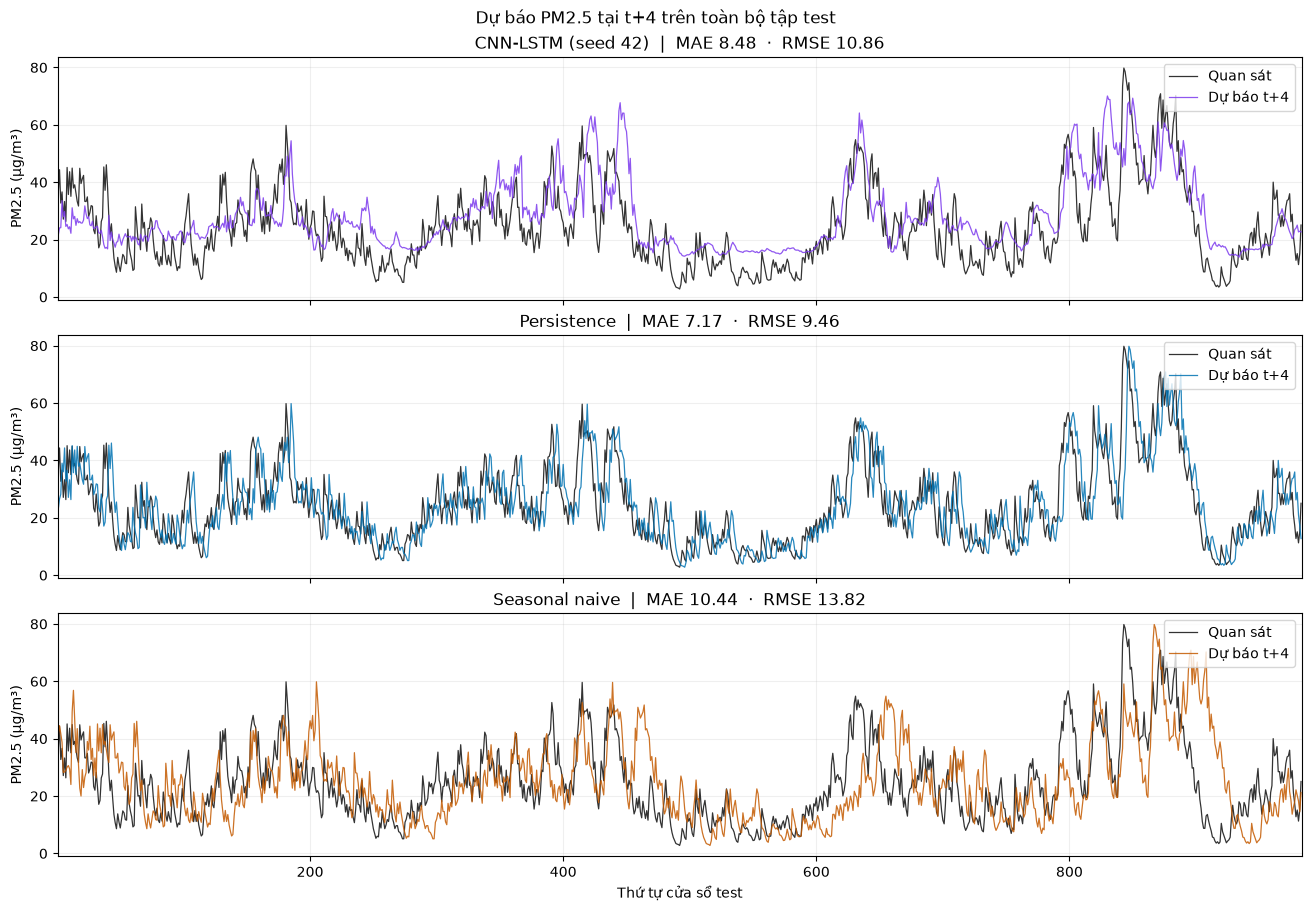

In [4]:
def plot_horizon(hour):
    column = hour - 1
    observed = y_raw[:, column]
    windows = range(1, len(observed) + 1)
    figure, axes = plt.subplots(
        len(predictions), 1, figsize=(13, 9), sharex=True, sharey=True,
        layout="constrained"
    )
    figure.suptitle(f"Dự báo PM2.5 tại t+{hour} trên toàn bộ tập test")
    colors = ("#7c3aed", "#0072b2", "#c45a00")
    for axis, (name, prediction), color in zip(axes, predictions.items(), colors):
        axis.plot(windows, observed, color="#333333", linewidth=0.9, label="Quan sát")
        axis.plot(
            windows, prediction[:, column], color=color, linewidth=0.9, alpha=0.85,
            label=f"Dự báo t+{hour}"
        )
        metrics = scores[name][column]
        axis.set(
            title=f"{name}  |  MAE {metrics['mae']:.2f}  ·  RMSE {metrics['rmse']:.2f}",
            ylabel="PM2.5 (µg/m³)"
        )
        axis.grid(alpha=0.2)
        axis.legend(loc="upper right")

    axes[-1].set(xlabel="Thứ tự cửa sổ test", xlim=(0.5, len(observed) + 0.5))
    return figure


plot_horizon(1)
plt.show()

output_dir = root / "visualizations" / "figures"
output_dir.mkdir(parents=True, exist_ok=True)
for hour in (2, 3, 4):
    figure = plot_horizon(hour)
    filename = f"{metadata['model_name']}_vs_baselines_test_t_plus_{hour}.png"
    output = output_dir / filename
    figure.savefig(output, dpi=180, facecolor="white")
    plt.show()